In [1]:
import numpy as np
import pandas as pd

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('Skyrun dataset.csv', parse_dates=['InvoiceDate']) #this identifies invoicedate column as datetime datatype rather than str.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   InvoiceDate  541909 non-null  datetime64[ns]
 2   CustomerID   406829 non-null  float64       
 3   StockCode    541909 non-null  object        
 4   Description  541909 non-null  object        
 5   Quantity     541909 non-null  int64         
 6   UnitPrice    541909 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [5]:
df.head()

,InvoiceNo,InvoiceDate,CustomerID,StockCode,Description,Quantity,UnitPrice,Country
0,536365,2024-12-01 08:26:00,17850.0,SC1734,Electronics,65,10.23,Egypt
1,536365,2024-12-01 08:26:00,17850.0,SC2088,Furniture,95,19.61,Mali
2,536365,2024-12-01 08:26:00,17850.0,SC3463,Books,78,61.49,Mali
3,536365,2024-12-01 08:26:00,17850.0,SC6228,Toys,15,24.73,South Africa
4,536365,2024-12-01 08:26:00,17850.0,SC2149,Toys,50,38.83,Rwanda


In [6]:
df.isnull().sum()  #to check for missing values.

,0
InvoiceNo,0
InvoiceDate,0
CustomerID,135080
StockCode,0
Description,0
Quantity,0
UnitPrice,0
Country,0


In [7]:
df = df.dropna(subset=['CustomerID']) # to drop/remove missing values

In [8]:
df.isnull().sum()

,0
InvoiceNo,0
InvoiceDate,0
CustomerID,0
StockCode,0
Description,0
Quantity,0
UnitPrice,0
Country,0


In [9]:
df['CustomerID'] = df['CustomerID'].astype(int).astype(str)  #to change CustomerID datatype from int to str.

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 406829 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    406829 non-null  object        
 1   InvoiceDate  406829 non-null  datetime64[ns]
 2   CustomerID   406829 non-null  object        
 3   StockCode    406829 non-null  object        
 4   Description  406829 non-null  object        
 5   Quantity     406829 non-null  int64         
 6   UnitPrice    406829 non-null  float64       
 7   Country      406829 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(5)
memory usage: 27.9+ MB


In [11]:
num_customers = df['CustomerID'].nunique()
print(f'Number of Unique Customers: {num_customers}')

num_customers = df['InvoiceNo'].nunique()
print(f'Number of Transactions: {num_customers}')

num_customers = df['StockCode'].nunique()
print(f'Number of Products: {num_customers}')

Number of Unique Customers: 4372
Number of Transactions: 22190
Number of Products: 9000


In [12]:
date_range = df['InvoiceDate'].agg(['min', 'max'])
print(f'Transaction Period: {date_range}')     #to get date range


Transaction Period: min   2024-12-01 08:26:00
max   2025-12-09 12:50:00
Name: InvoiceDate, dtype: datetime64[ns]


In [13]:
print(f'Rows with Negative Quantity: {(df.Quantity <= 0).sum()}')
print(f'Rows with Negative Unit Price: {(df.UnitPrice <= 0).sum()}')

Rows with Negative Quantity: 0
Rows with Negative Unit Price: 0


In [14]:
top_countries = df.groupby('Country')['CustomerID'].nunique().sort_values(ascending=False).head()

/tmp/ipykernel_2274/2782188312.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.values, y=top_countries.index, palette='viridis')


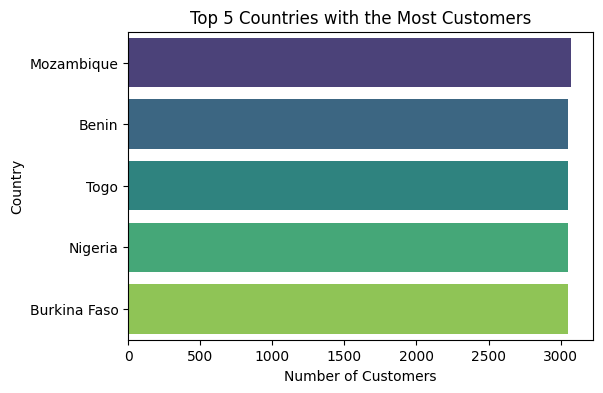

In [15]:
plt.figure(figsize=(6,4))
sns.barplot(x=top_countries.values, y=top_countries.index, palette='viridis')
plt.xlabel('Number of Customers')
plt.ylabel('Country')
plt.title('Top 5 Countries with the Most Customers')
plt.show()

/tmp/ipykernel_2274/3410703862.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.values, y=top_countries.index, palette='viridis')


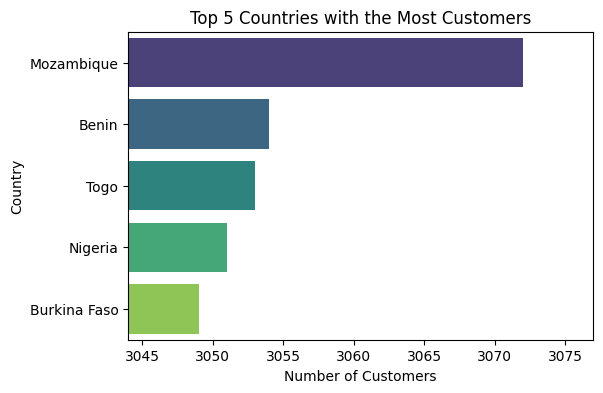

In [16]:
plt.figure(figsize=(6,4))
sns.barplot(x=top_countries.values, y=top_countries.index, palette='viridis')
plt.xlim(min(top_countries.values)-5, max(top_countries.values)+5)
plt.xlabel('Number of Customers')
plt.ylabel('Country')
plt.title('Top 5 Countries with the Most Customers')
plt.show()

In [17]:
df['InvoiceMonth'] = df['InvoiceDate'].dt.to_period('M')

In [18]:
df['Revenue'] = df['Quantity'] * df['UnitPrice']

In [19]:
df.head()

,InvoiceNo,InvoiceDate,CustomerID,StockCode,Description,Quantity,UnitPrice,Country,InvoiceMonth,Revenue
0,536365,2024-12-01 08:26:00,17850,SC1734,Electronics,65,10.23,Egypt,2024-12,664.95
1,536365,2024-12-01 08:26:00,17850,SC2088,Furniture,95,19.61,Mali,2024-12,1862.95
2,536365,2024-12-01 08:26:00,17850,SC3463,Books,78,61.49,Mali,2024-12,4796.22
3,536365,2024-12-01 08:26:00,17850,SC6228,Toys,15,24.73,South Africa,2024-12,370.95
4,536365,2024-12-01 08:26:00,17850,SC2149,Toys,50,38.83,Rwanda,2024-12,1941.50


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 406829 entries, 0 to 541908
Data columns (total 10 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   InvoiceNo     406829 non-null  object        
 1   InvoiceDate   406829 non-null  datetime64[ns]
 2   CustomerID    406829 non-null  object        
 3   StockCode     406829 non-null  object        
 4   Description   406829 non-null  object        
 5   Quantity      406829 non-null  int64         
 6   UnitPrice     406829 non-null  float64       
 7   Country       406829 non-null  object        
 8   InvoiceMonth  406829 non-null  period[M]     
 9   Revenue       406829 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(1), object(5), period[M](1)
memory usage: 34.1+ MB


In [21]:
monthly_sales = df.groupby('InvoiceMonth')['Revenue'].sum().reset_index()

In [22]:
monthly_sales.InvoiceMonth = monthly_sales.InvoiceMonth.astype(str)

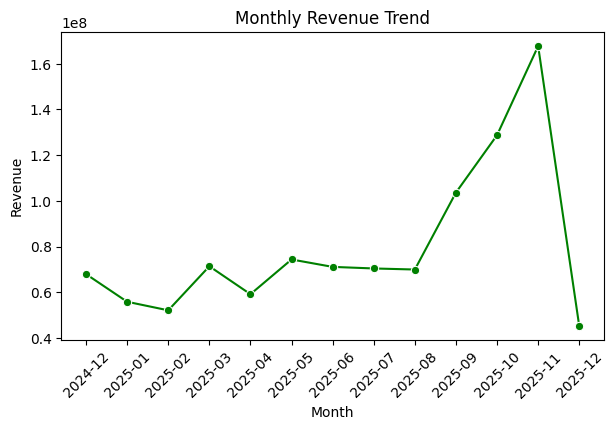

In [23]:
plt.figure(figsize=(7,4))
sns.lineplot(x='InvoiceMonth', y='Revenue', data=monthly_sales, marker='o', color='green')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.title('Monthly Revenue Trend')
plt.show()

In [24]:
#cohort analysis
# Tracker - Month of first purchase.

df.head()

,InvoiceNo,InvoiceDate,CustomerID,StockCode,Description,Quantity,UnitPrice,Country,InvoiceMonth,Revenue
0,536365,2024-12-01 08:26:00,17850,SC1734,Electronics,65,10.23,Egypt,2024-12,664.95
1,536365,2024-12-01 08:26:00,17850,SC2088,Furniture,95,19.61,Mali,2024-12,1862.95
2,536365,2024-12-01 08:26:00,17850,SC3463,Books,78,61.49,Mali,2024-12,4796.22
3,536365,2024-12-01 08:26:00,17850,SC6228,Toys,15,24.73,South Africa,2024-12,370.95
4,536365,2024-12-01 08:26:00,17850,SC2149,Toys,50,38.83,Rwanda,2024-12,1941.50


In [25]:
cohort_data = df.groupby('CustomerID')['InvoiceMonth'].min() # to group the data and call the firstmonth

In [26]:
cohort_data.name = 'CohortMonth'

In [29]:
cohort_data.head(20)

,CohortMonth
CustomerID,
12346,2025-01
12347,2024-12
12348,2024-12
12349,2025-11
12350,2025-02
12352,2025-02
12353,2025-05
12354,2025-04
12355,2025-05


In [30]:
df = df.merge(cohort_data, on='CustomerID') #we are mapping with customerid to get all the month of fisrt acquisition

In [32]:
df.head(30)

,InvoiceNo,InvoiceDate,CustomerID,StockCode,Description,Quantity,UnitPrice,Country,InvoiceMonth,Revenue,CohortMonth
0,536365,2024-12-01 08:26:00,17850,SC1734,Electronics,65,10.23,Egypt,2024-12,664.95,2024-12
1,536365,2024-12-01 08:26:00,17850,SC2088,Furniture,95,19.61,Mali,2024-12,1862.95,2024-12
2,536365,2024-12-01 08:26:00,17850,SC3463,Books,78,61.49,Mali,2024-12,4796.22,2024-12
3,536365,2024-12-01 08:26:00,17850,SC6228,Toys,15,24.73,South Africa,2024-12,370.95,2024-12
4,536365,2024-12-01 08:26:00,17850,SC2149,Toys,50,38.83,Rwanda,2024-12,1941.50,2024-12
5,536365,2024-12-01 08:26:00,17850,SC7895,Toys,41,45.31,Sierra Leone,2024-12,1857.71,2024-12
6,536365,2024-12-01 08:26:00,17850,SC8608,Books,44,39.31,Benin,2024-12,1729.64,2024-12
7,536366,2024-12-01 08:28:00,17850,SC3216,Toys,47,77.35,Burkina Faso,2024-12,3635.45,2024-12
8,536366,2024-12-01 08:28:00,17850,SC1236,Kitchenware,19,35.11,Nigeria,2024-12,667.09,2024-12
9,536367,2024-12-01 08:34:00,13047,SC4513,Furniture,55,3.21,Cote d'Ivoire,2024-12,176.55,2024-12


In [33]:
#to see difference between the lowest and highest pruchase per invoicemonth

invoice_year, invoice_month = df['InvoiceMonth'].dt.year, df['InvoiceMonth'].dt.month
cohort_year, cohort_month = df['CohortMonth'].dt.year, df['CohortMonth'].dt.month

In [34]:
# to check for year difference to calculate cohort index

year_diff = invoice_year - cohort_year
month_diff = invoice_month - cohort_month

In [35]:
year_diff, month_diff

(0         0
 1         0
 2         0
 3         0
 4         0
          ..
 406824    0
 406825    0
 406826    0
 406827    0
 406828    0
 Length: 406829, dtype: int64,
 0         0
 1         0
 2         0
 3         0
 4         0
          ..
 406824    4
 406825    4
 406826    4
 406827    4
 406828    4
 Length: 406829, dtype: int64)

In [37]:
df['CohortIndex'] = year_diff * 12 + month_diff + 1  #Cause month changes every 1 month.
df.tail(10)                                    # CohortIndex tells you the amount of times i customer has purchased over the month.

,InvoiceNo,InvoiceDate,CustomerID,StockCode,Description,Quantity,UnitPrice,Country,InvoiceMonth,Revenue,CohortMonth,CohortIndex
406819,581587,2025-12-09 12:50:00,12680,SC1744,Furniture,5,63.49,Nigeria,2025-12,317.45,2025-08,5
406820,581587,2025-12-09 12:50:00,12680,SC3155,Toys,28,17.31,Nigeria,2025-12,484.68,2025-08,5
406821,581587,2025-12-09 12:50:00,12680,SC2880,Electronics,41,78.23,Tunisia,2025-12,3207.43,2025-08,5
406822,581587,2025-12-09 12:50:00,12680,SC4436,Sports Equipment,58,39.06,Sudan,2025-12,2265.48,2025-08,5
406823,581587,2025-12-09 12:50:00,12680,SC9552,Furniture,74,5.99,Ethiopia,2025-12,443.26,2025-08,5
406824,581587,2025-12-09 12:50:00,12680,SC5440,Furniture,25,36.53,Mozambique,2025-12,913.25,2025-08,5
406825,581587,2025-12-09 12:50:00,12680,SC3576,Cloths,94,90.65,Tunisia,2025-12,8521.10,2025-08,5
406826,581587,2025-12-09 12:50:00,12680,SC5283,Furniture,14,40.07,Somalia,2025-12,560.98,2025-08,5
406827,581587,2025-12-09 12:50:00,12680,SC1099,Cosmetics,45,79.83,Senegal,2025-12,3592.35,2025-08,5
406828,581587,2025-12-09 12:50:00,12680,SC9276,Toys,6,46.62,Ethiopia,2025-12,279.72,2025-08,5


In [38]:
cohort_counts = df.groupby(['CohortMonth', 'CohortIndex'])['CustomerID'].nunique().reset_index()

In [52]:
cohort_pivot = cohort_counts.pivot(index='CohortMonth', columns='CohortIndex', values='CustomerID')

In [53]:
cohort_pivot

CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohortMonth,,,,,,,,,,,,,
2024-12,948.0,362.0,317.0,367.0,341.0,376.0,360.0,336.0,336.0,374.0,354.0,474.0,260.0
2025-01,421.0,101.0,119.0,102.0,138.0,126.0,110.0,108.0,131.0,146.0,155.0,63.0,NaN
2025-02,380.0,94.0,73.0,106.0,102.0,94.0,97.0,107.0,98.0,119.0,35.0,NaN,NaN
2025-03,440.0,84.0,112.0,96.0,102.0,78.0,116.0,105.0,127.0,39.0,NaN,NaN,NaN
2025-04,299.0,68.0,66.0,63.0,62.0,71.0,69.0,78.0,25.0,NaN,NaN,NaN,NaN
2025-05,279.0,66.0,48.0,48.0,60.0,68.0,74.0,29.0,NaN,NaN,NaN,NaN,NaN
2025-06,235.0,49.0,44.0,64.0,58.0,79.0,24.0,NaN,NaN,NaN,NaN,NaN,NaN
2025-07,191.0,40.0,39.0,44.0,52.0,22.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-08,167.0,42.0,42.0,42.0,23.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [54]:
#generating retention table to enable stakeholder make sense of the data through visualization

cohort_size = cohort_pivot.iloc[:,0]
retention = cohort_pivot.divide(cohort_size, axis=0)
retention

CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohortMonth,,,,,,,,,,,,,
2024-12,1.0,0.381857,0.334388,0.387131,0.359705,0.396624,0.379747,0.354430,0.354430,0.394515,0.373418,0.500000,0.274262
2025-01,1.0,0.239905,0.282660,0.242280,0.327791,0.299287,0.261283,0.256532,0.311164,0.346793,0.368171,0.149644,NaN
2025-02,1.0,0.247368,0.192105,0.278947,0.268421,0.247368,0.255263,0.281579,0.257895,0.313158,0.092105,NaN,NaN
2025-03,1.0,0.190909,0.254545,0.218182,0.231818,0.177273,0.263636,0.238636,0.288636,0.088636,NaN,NaN,NaN
2025-04,1.0,0.227425,0.220736,0.210702,0.207358,0.237458,0.230769,0.260870,0.083612,NaN,NaN,NaN,NaN
2025-05,1.0,0.236559,0.172043,0.172043,0.215054,0.243728,0.265233,0.103943,NaN,NaN,NaN,NaN,NaN
2025-06,1.0,0.208511,0.187234,0.272340,0.246809,0.336170,0.102128,NaN,NaN,NaN,NaN,NaN,NaN
2025-07,1.0,0.209424,0.204188,0.230366,0.272251,0.115183,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-08,1.0,0.251497,0.251497,0.251497,0.137725,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


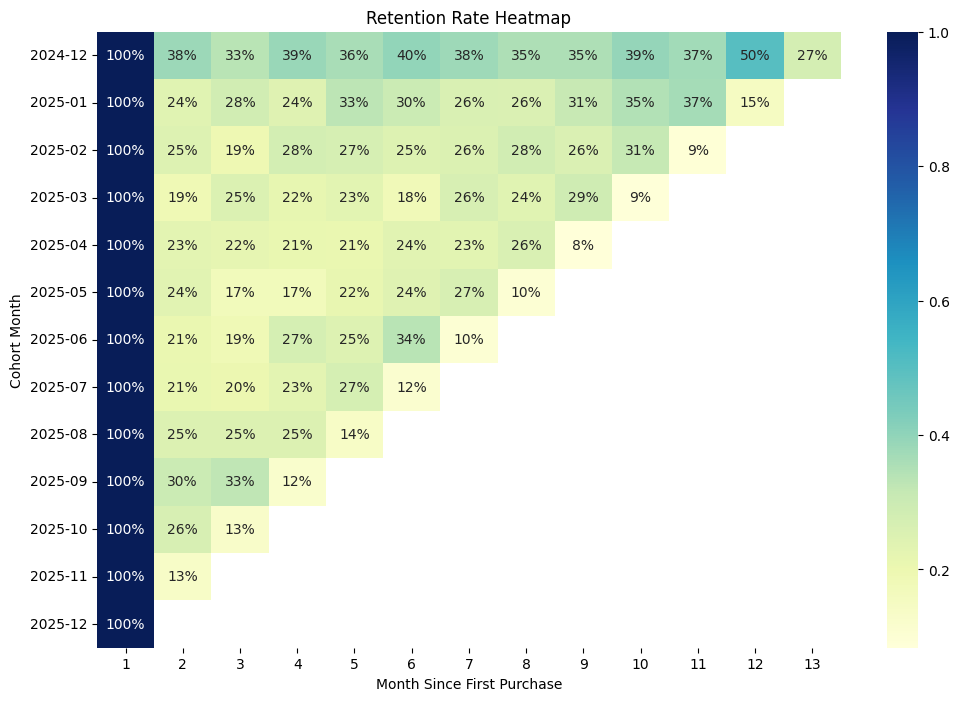

In [55]:
plt.figure(figsize=(12,8))
sns.heatmap(retention, annot=True, fmt='.0%', cmap='YlGnBu')
plt.title('Retention Rate Heatmap')
plt.xlabel('Month Since First Purchase')
plt.ylabel('Cohort Month')
plt.savefig('retention_heatmap.png')
plt.show()

In [56]:
# RFM A nalysis

# cohort analysis always leads to RFM analysis cause we are dealing with customers and RFM deals with grouping those customers in Recency, frequency and how much they spent.

reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)
reference_date

Timestamp('2025-12-10 12:50:00')

In [57]:
df.columns

Index(['InvoiceNo', 'InvoiceDate', 'CustomerID', 'StockCode', 'Description',
       'Quantity', 'UnitPrice', 'Country', 'InvoiceMonth', 'Revenue',
       'CohortMonth', 'CohortIndex'],
      dtype='object')

In [60]:
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,         # lambda calculates Recency
    'InvoiceNo': pd.Series.nunique,      # calculates the frequency
    'Revenue': 'sum'      # calculates the monetary value
}).reset_index()

In [61]:
rfm.columns = ['CustomerID', 'Recency_days', 'Frequency', 'Monetary']
rfm.head()

,CustomerID,Recency_days,Frequency,Monetary
0,12346,326,2,5342.40
1,12347,2,7,431501.00
2,12348,75,4,82378.47
3,12349,19,1,176075.12
4,12350,310,1,48173.37


In [63]:
# Building an unserpervised ML model to group this customers together.

x = rfm[['Recency_days', 'Frequency', 'Monetary']].copy()
x.head()



,Recency_days,Frequency,Monetary
0,326,2,5342.40
1,2,7,431501.00
2,75,4,82378.47
3,19,1,176075.12
4,310,1,48173.37


In [64]:
from sklearn.preprocessing import StandardScaler

In [65]:
ss = StandardScaler()

In [66]:
x_scaled = ss.fit_transform(x)

In [68]:
x_scaled[:10]

array([[ 2.32202285, -0.32936215, -0.39022789],
       [-0.89373323,  0.20610242,  0.32673724],
       [-0.1691956 , -0.11517632, -0.26062315],
       [-0.72500529, -0.43645506, -0.1029888 ],
       [ 2.16322008, -0.43645506, -0.31816948],
       [-0.55627735,  0.63447407,  0.00719488],
       [ 1.11115173, -0.43645506, -0.39188422],
       [ 1.38905658, -0.43645506, -0.12747201],
       [ 1.21040346, -0.43645506, -0.33587679],
       [-0.6853046 , -0.22226923, -0.12731136]])

In [69]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [70]:
from yellowbrick.cluster import KElbowVisualizer

In [73]:
model = KMeans(random_state=30)

KElbowVisualizer(ax=<Axes: >, estimator=KMeans(n_clusters=9, random_state=30),
                 k=(2, 10))

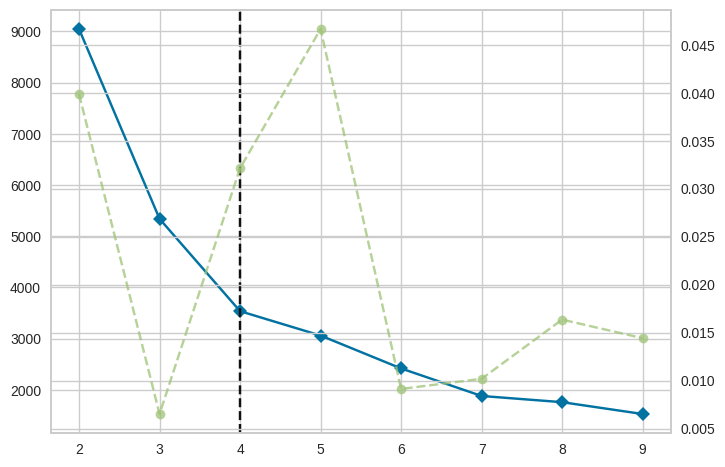

In [75]:
v = KElbowVisualizer(model, k=(2,10))
v.fit(x_scaled)

In [79]:
final_model = KMeans(n_clusters=4, random_state=42)  # cause 4 is the best total number of cluster point

In [80]:
final_model.fit(x_scaled)

KMeans(n_clusters=4, random_state=42)

In [81]:
rfm.head()

,CustomerID,Recency_days,Frequency,Monetary
0,12346,326,2,5342.40
1,12347,2,7,431501.00
2,12348,75,4,82378.47
3,12349,19,1,176075.12
4,12350,310,1,48173.37


In [82]:
rfm['Cluster'] = final_model.labels_

In [83]:
rfm.head(10)

,CustomerID,Recency_days,Frequency,Monetary,Cluster
0,12346,326,2,5342.40,1
1,12347,2,7,431501.00,0
2,12348,75,4,82378.47,0
3,12349,19,1,176075.12,0
4,12350,310,1,48173.37,1
5,12352,36,11,241567.46,0
6,12353,204,1,4357.89,1
7,12354,232,1,161522.49,1
8,12355,214,1,37648.28,1
9,12356,23,3,161617.98,0


In [87]:
cluster_profile = rfm.groupby('Cluster').agg({
    'Recency_days': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'CustomerID': 'count'
}).rename(columns={'CustomerID': 'NumCustomers'}).round(1)

In [88]:
cluster_profile  # 2 is best performing customers WHILE 1 is worst performing.

,Recency_days,Frequency,Monetary,NumCustomers
Cluster,,,,
0,43.4,4.2,195421.0,3023
1,248.9,1.8,69191.6,1077
2,1.7,153.5,12345024.6,6
3,11.8,25.3,1120633.6,266


In [89]:
cluster_names = {
    0: 'Good Customers',
    1: 'At Risk / Lost Customers',
    2: 'Ultra VIPs',
    3: 'Regulars'
}

In [90]:
cluster_profile['Segment'] = cluster_profile.index.map(cluster_names)

In [91]:
df_plot = cluster_profile.copy()
df_plot[['Recency_days', 'Frequency', 'Monetary']] =(
    df_plot[['Recency_days', 'Frequency', 'Monetary']].apply(lambda x: x / x.max())
)

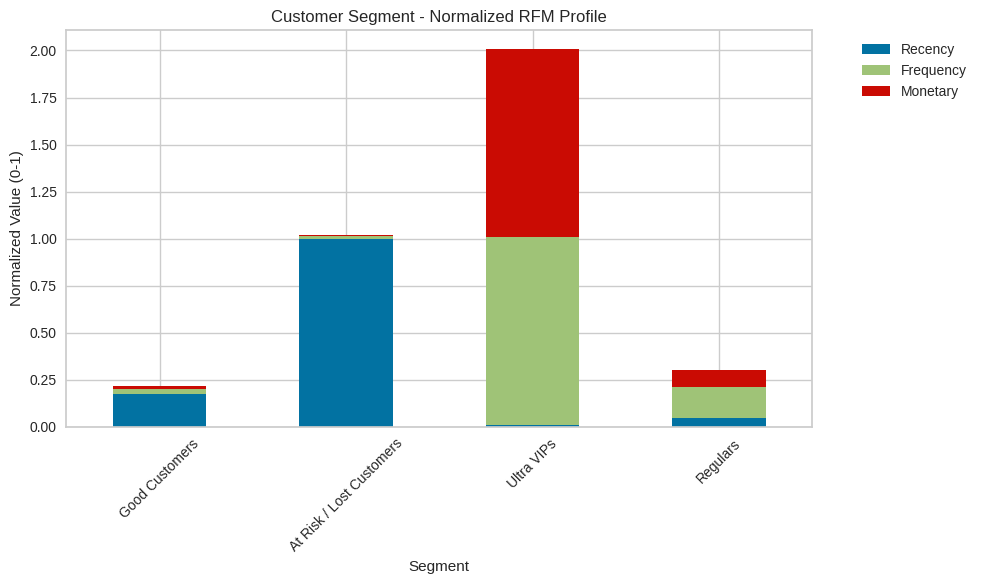

<Figure size 800x550 with 0 Axes>

In [94]:
df_plot.set_index('Segment')[['Recency_days', 'Frequency', 'Monetary']].plot(
    kind='bar', stacked=True, figsize=(10,6)
)
plt.title('Customer Segment - Normalized RFM Profile')
plt.ylabel('Normalized Value (0-1)')
plt.xticks(rotation=45)
plt.legend(['Recency', 'Frequency', 'Monetary'], bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()
plt.savefig('customer_segment.png')